In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE

In [2]:
df_train_data_clean = pd.read_csv("train_data_clean.csv")
df_test_data = pd.read_csv("test_data.csv")
df_train_data_clean = df_train_data_clean.drop(columns = ["Unnamed: 0", "case_id", "patientid"])
df_train_data_clean

,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Bed Grade,City_Code_Patient,Type of Admission,Severity of Illness,Age,Stay,Numero_registros_paciente
0,8,c,3,Z,3,radiotherapy,R,2.0,7.0,Emergency,Extreme,51-60,0-10,14
1,2,c,5,Z,2,radiotherapy,S,2.0,7.0,Trauma,Extreme,51-60,41-50,14
2,10,e,1,X,2,anesthesia,S,2.0,7.0,Trauma,Extreme,51-60,31-40,14
3,26,b,2,Y,2,radiotherapy,R,2.0,7.0,Trauma,Extreme,51-60,41-50,14
4,26,b,2,Y,2,radiotherapy,S,2.0,7.0,Trauma,Extreme,51-60,41-50,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318320,6,a,6,X,3,radiotherapy,Q,4.0,23.0,Emergency,Moderate,41-50,11-20,1
318321,24,a,1,X,2,anesthesia,Q,4.0,8.0,Urgent,Moderate,81-90,31-40,1
318322,7,a,4,X,3,gynecology,R,4.0,10.0,Emergency,Minor,71-80,11-20,1
318323,11,b,2,Y,3,anesthesia,Q,3.0,8.0,Trauma,Minor,11-20,11-20,1


## ANALISIS EXPLORATORIO

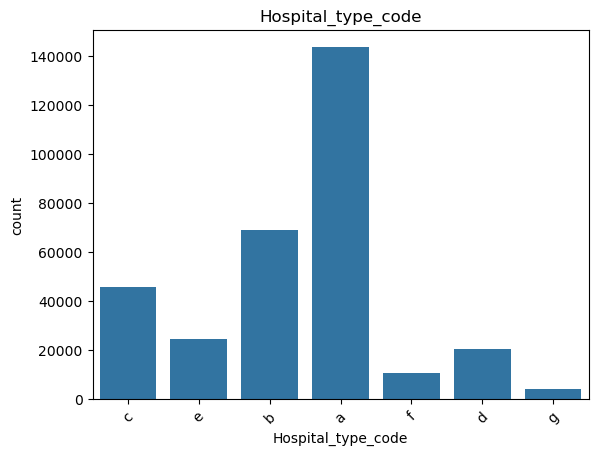

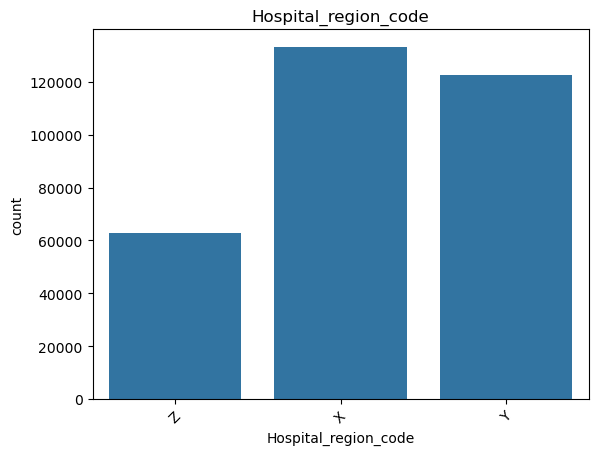

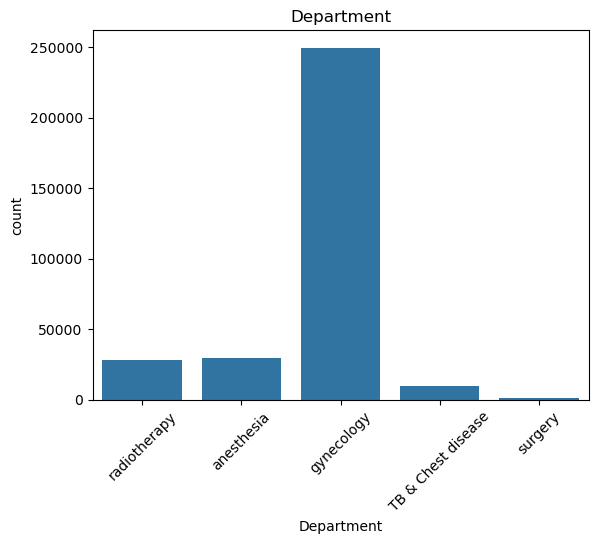

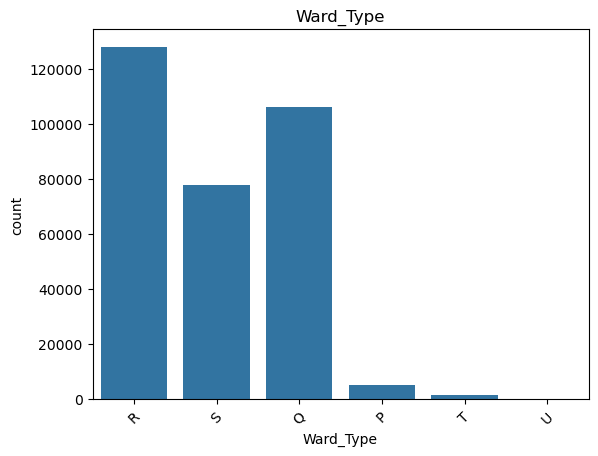

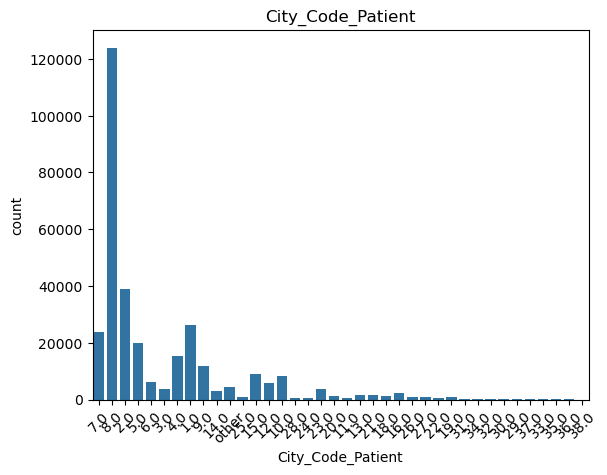

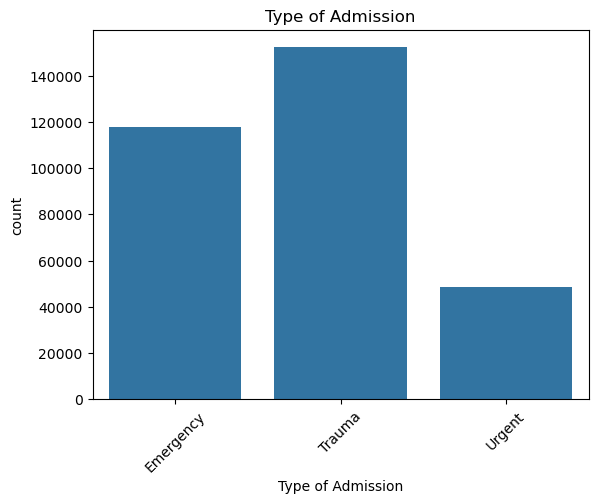

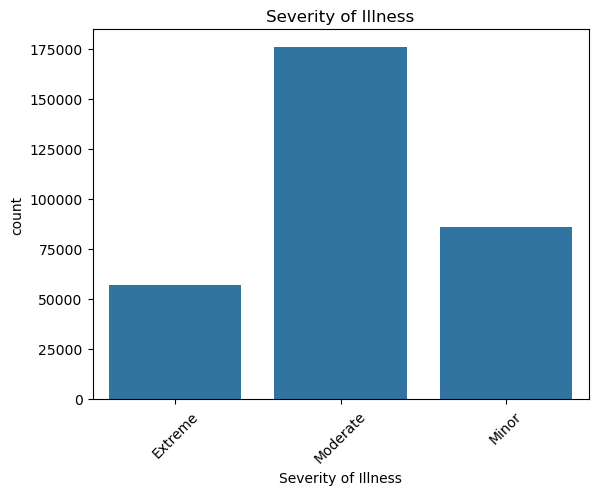

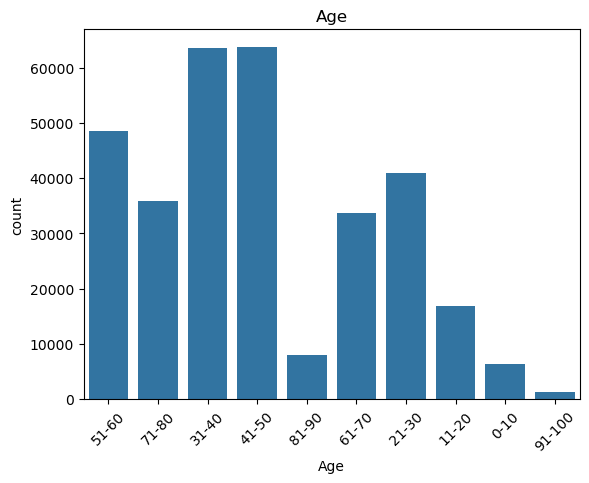

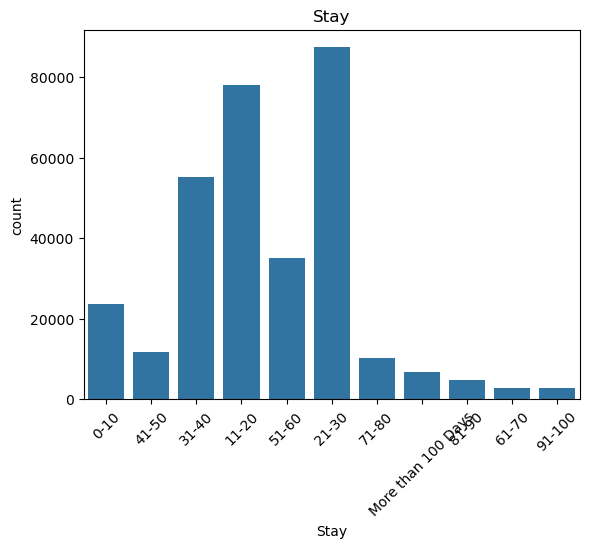

In [3]:
filtro = df_train_data_clean.dtypes == "object"

for columna in df_train_data_clean.columns[filtro]:
    sns.countplot(data = df_train_data_clean, x = columna)
    plt.title(columna)
    plt.xticks(rotation = 45)
    plt.show()

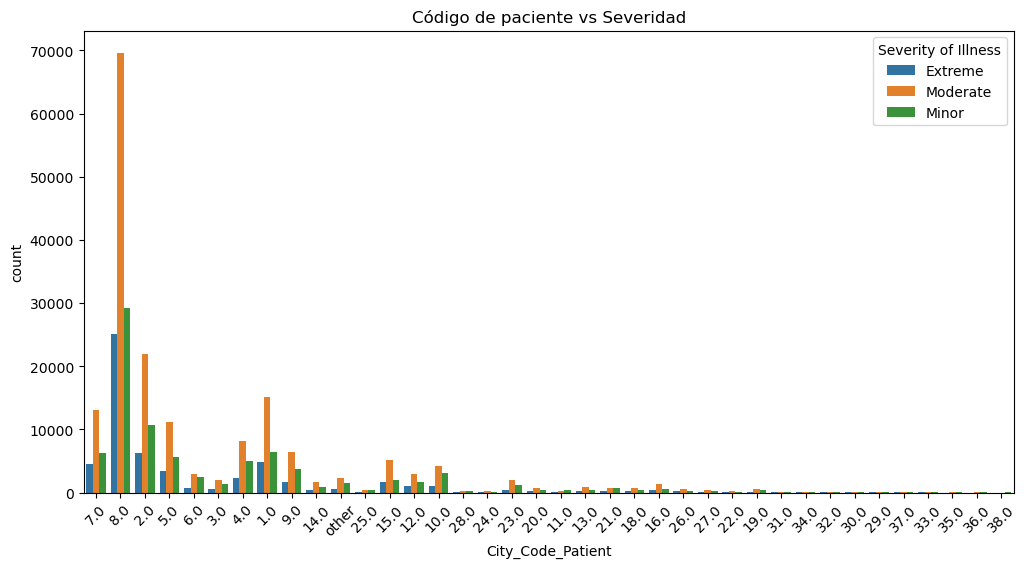

In [4]:
plt.figure(figsize=(12,6))
sns.countplot(data=df_train_data_clean, x="City_Code_Patient", hue="Severity of Illness")
plt.xticks(rotation=45)
plt.title("Código de paciente vs Severidad")
plt.show()

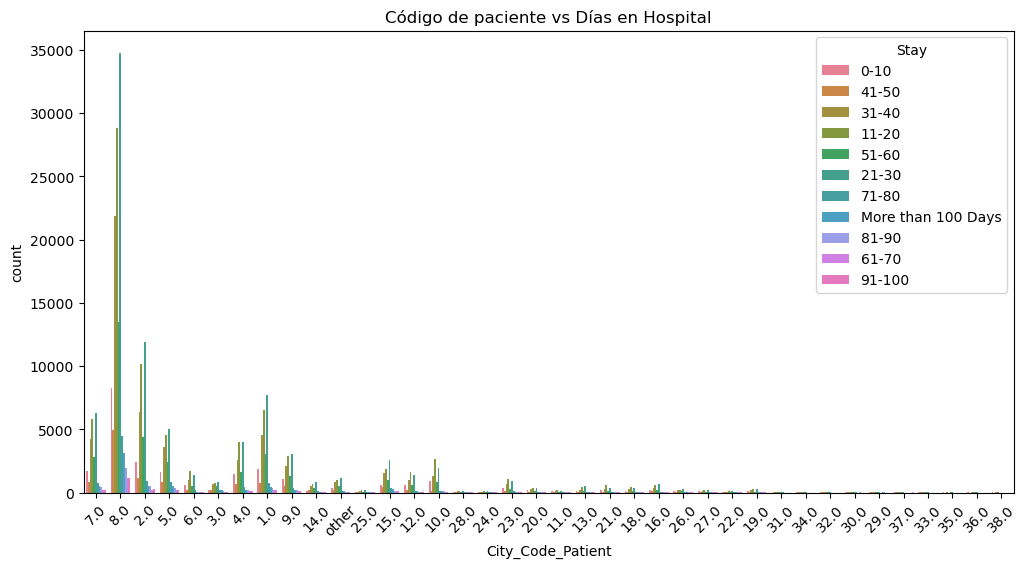

In [5]:
plt.figure(figsize=(12,6))
sns.countplot(data=df_train_data_clean, x="City_Code_Patient", hue="Stay")
plt.xticks(rotation=45)
plt.title("Código de paciente vs Días en Hospital")
plt.show()

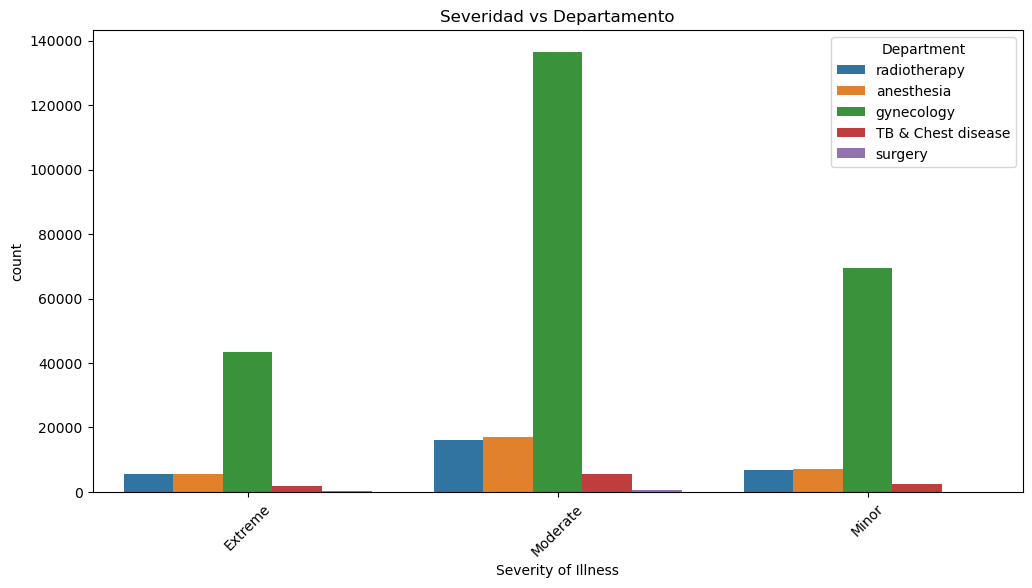

In [6]:
plt.figure(figsize=(12,6))
sns.countplot(data=df_train_data_clean, x="Severity of Illness", hue="Department")
plt.xticks(rotation=45)
plt.title("Severidad vs Departamento")
plt.show()

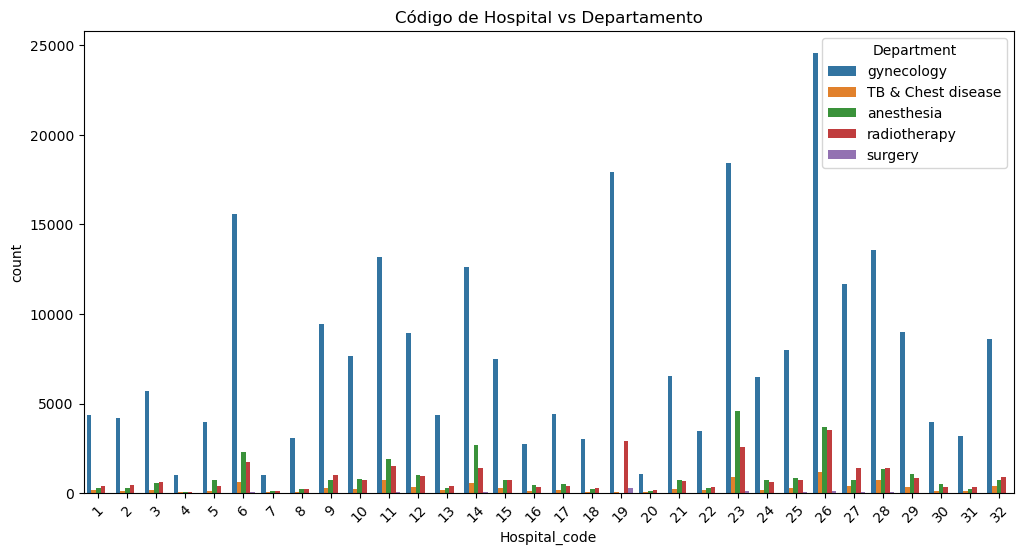

In [7]:
plt.figure(figsize=(12,6))
sns.countplot(
    data = df_train_data_clean,
    x="Hospital_code", 
    hue="Department")
plt.xticks(rotation = 45)
plt.title("Código de Hospital vs Departamento")
plt.show()

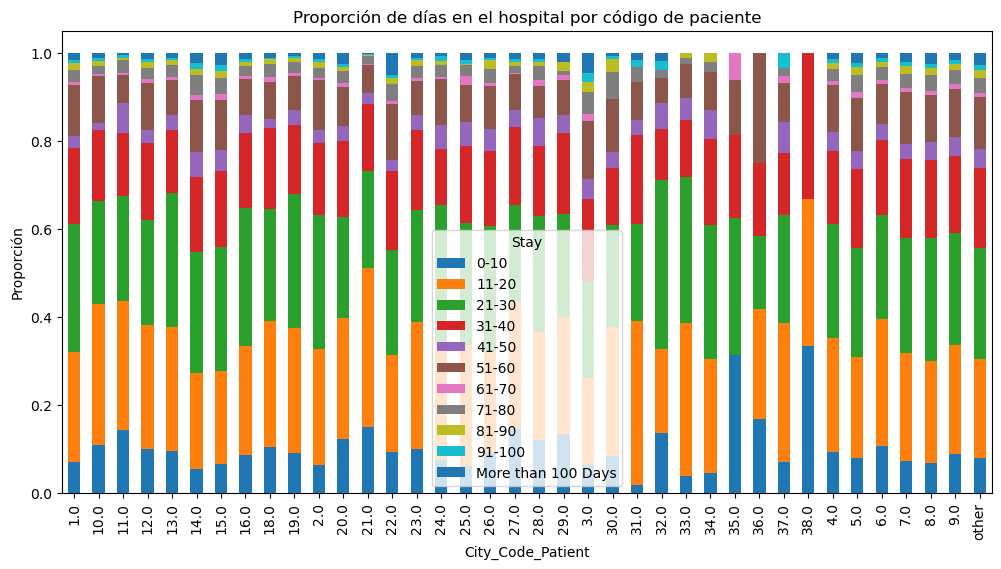

In [8]:
#Queremos ver cual es la proporción por paciente en relación a los departamentos
tabla = pd.crosstab(df_train_data_clean["City_Code_Patient"], df_train_data_clean["Stay"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de Días en el Hospital por código ciudad de paciente")
plt.ylabel("Proporción")
plt.show()

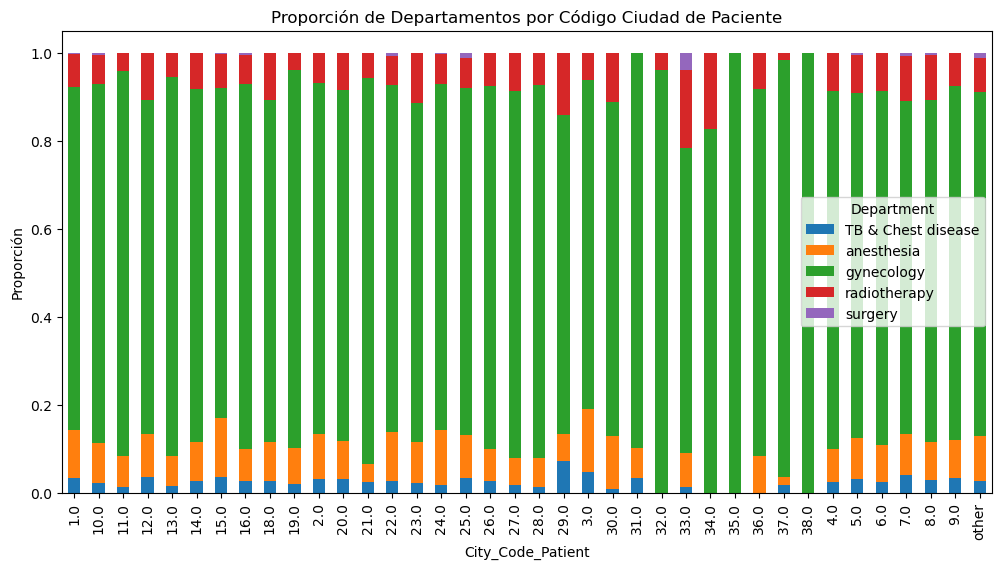

In [49]:
tabla = pd.crosstab(df_train_data_clean["City_Code_Patient"], df_train_data_clean["Department"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de Departamentos por Código Ciudad de Paciente")
plt.ylabel("Proporción")
plt.show()

## COMPROBAMOS LA IMPORTANCIA DEL GRADO DE CAMA

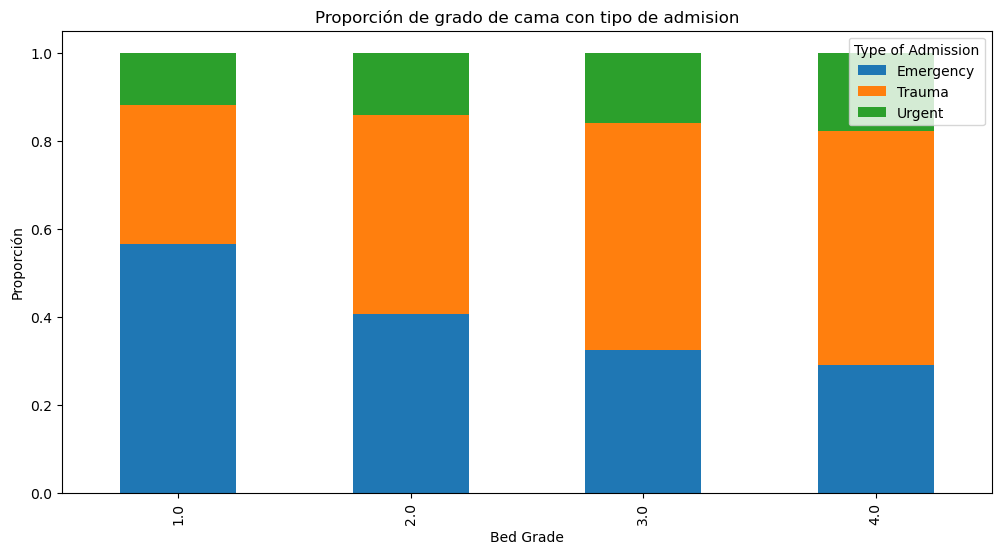

In [10]:
tabla = pd.crosstab(df_train_data_clean["Bed Grade"], df_train_data_clean["Type of Admission"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de grado de cama con tipo de admision")
plt.ylabel("Proporción")
plt.show()

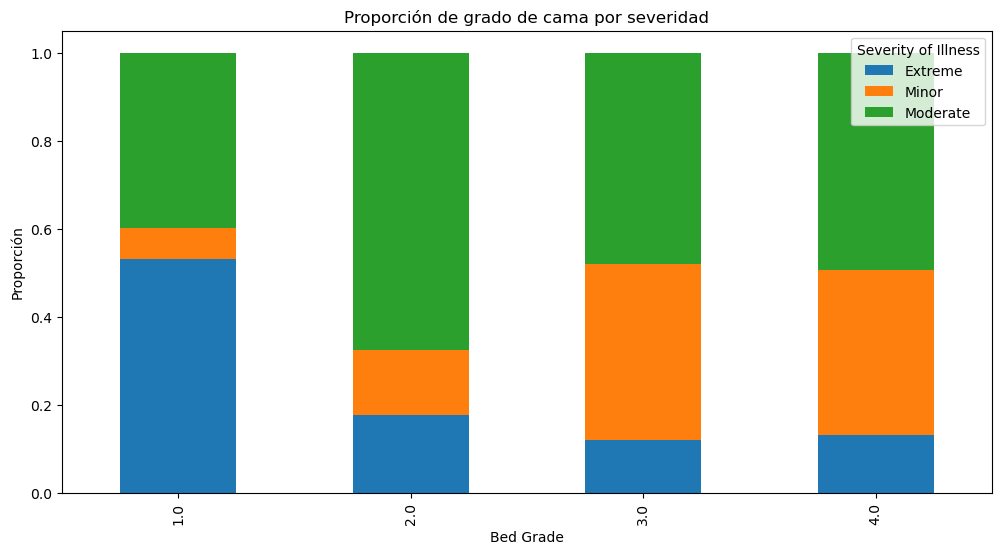

In [11]:
tabla = pd.crosstab(df_train_data_clean["Bed Grade"], df_train_data_clean["Severity of Illness"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de grado de cama por severidad")
plt.ylabel("Proporción")
plt.show()

## COMPROBAMOS LA IMPORTANCIA DE LAS CAMAS LIBRES

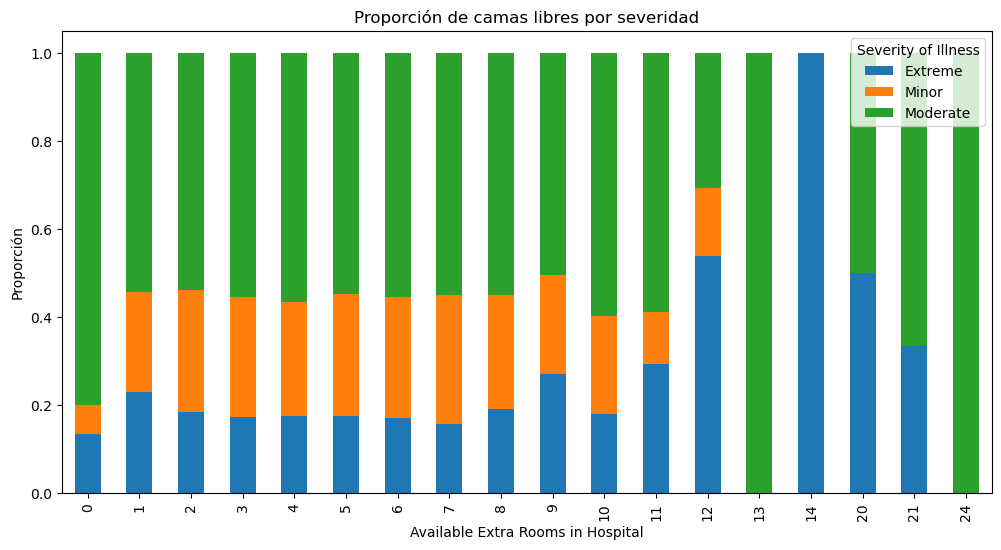

In [12]:
tabla = pd.crosstab(df_train_data_clean["Available Extra Rooms in Hospital"], df_train_data_clean["Severity of Illness"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de camas libres por severidad")
plt.ylabel("Proporción")
plt.show()

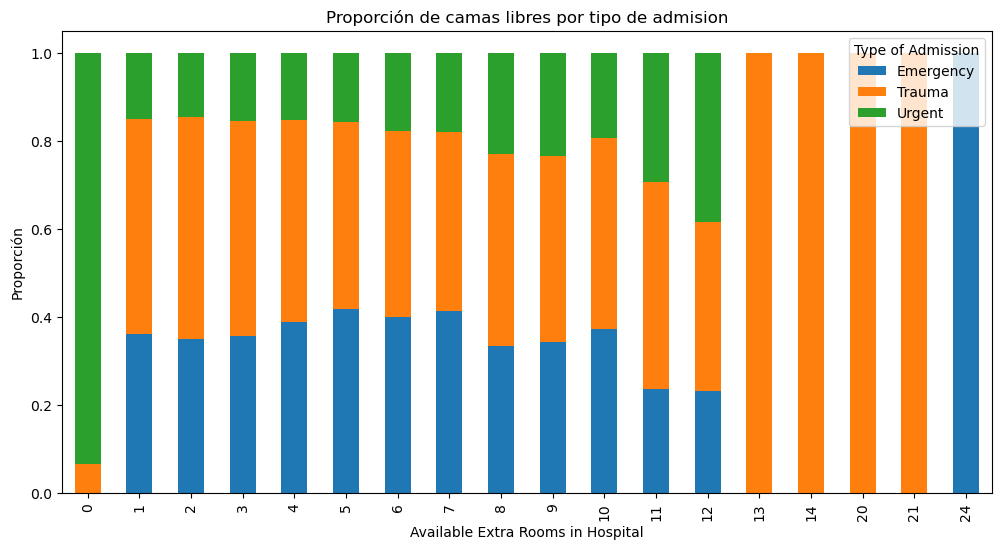

In [13]:
tabla = pd.crosstab(df_train_data_clean["Available Extra Rooms in Hospital"], df_train_data_clean["Type of Admission"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de camas libres por tipo de admision")
plt.ylabel("Proporción")
plt.show()

## COMPROBAMOS LA IMPORTANCIA DE TIPO DE PLANTA

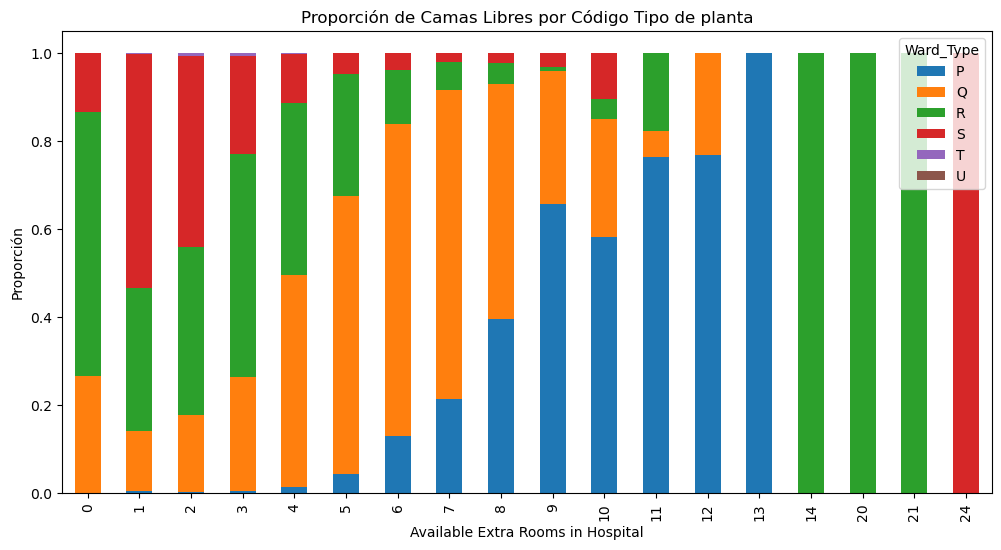

In [47]:
tabla = pd.crosstab(df_train_data_clean["Available Extra Rooms in Hospital"], df_train_data_clean["Ward_Type"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de Camas Libres por Código Tipo de planta")
plt.ylabel("Proporción")
plt.show()

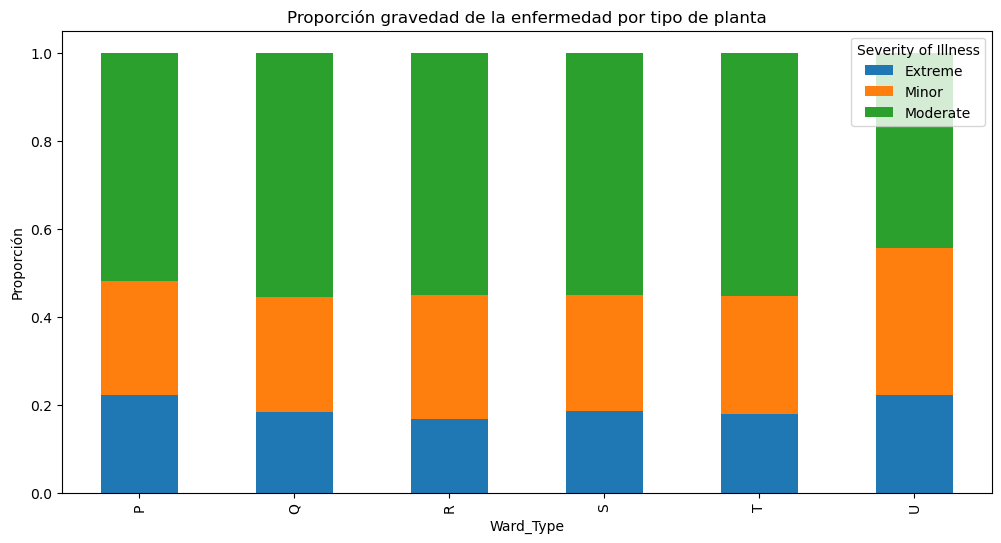

In [15]:
tabla = pd.crosstab(df_train_data_clean["Ward_Type"], df_train_data_clean["Severity of Illness"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción gravedad de la enfermedad por tipo de planta")
plt.ylabel("Proporción")
plt.show()

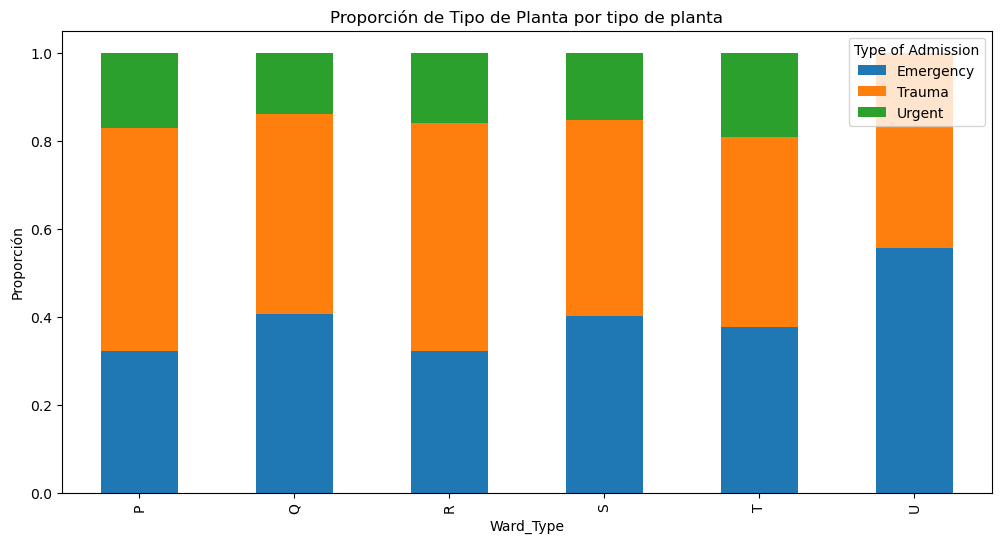

In [45]:
tabla = pd.crosstab(df_train_data_clean["Ward_Type"], df_train_data_clean["Type of Admission"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de Tipo de Planta por tipo de planta")
plt.ylabel("Proporción")
plt.show()

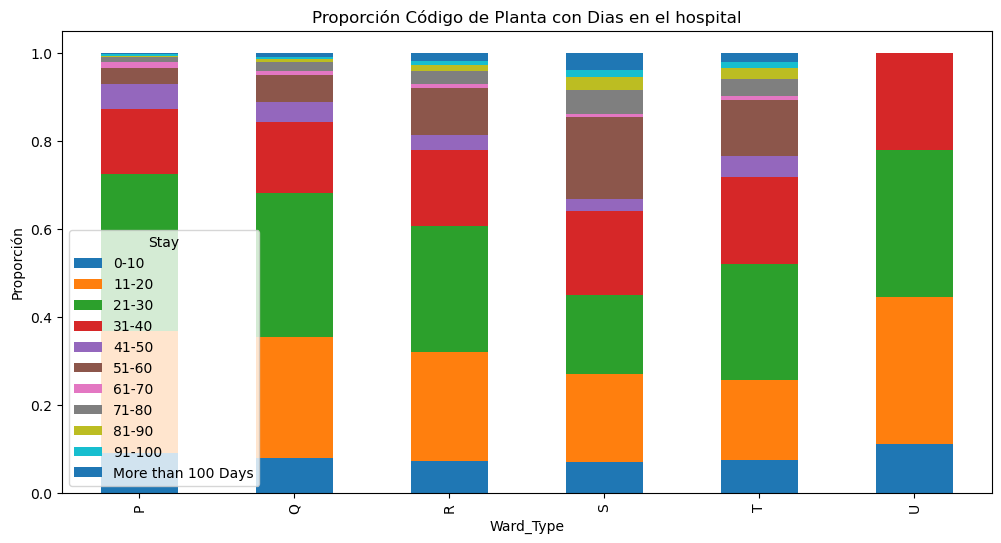

In [46]:
tabla = pd.crosstab(df_train_data_clean["Ward_Type"], df_train_data_clean["Stay"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción Código de Planta con Dias en el hospital")
plt.ylabel("Proporción")
plt.show()

## COMPROBAMOS QUE INFLUYE REALMENTE LA EDAD POR TRAMOS

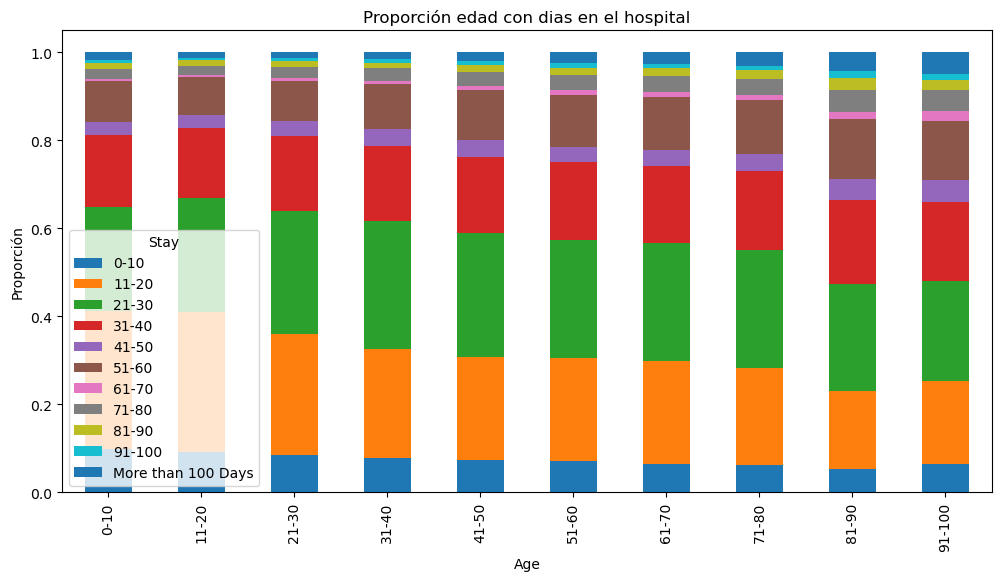

In [18]:
tabla = pd.crosstab(df_train_data_clean["Age"], df_train_data_clean["Stay"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción edad con dias en el hospital")
plt.ylabel("Proporción")
plt.show()

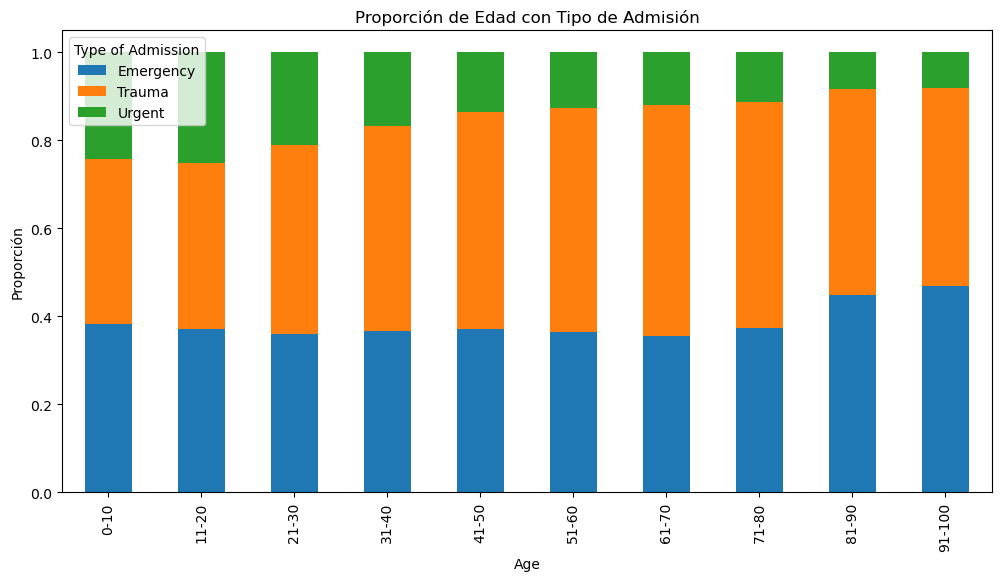

In [19]:
tabla = pd.crosstab(df_train_data_clean["Age"], df_train_data_clean["Type of Admission"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de Edad con Tipo de Admisión")
plt.ylabel("Proporción")
plt.show()

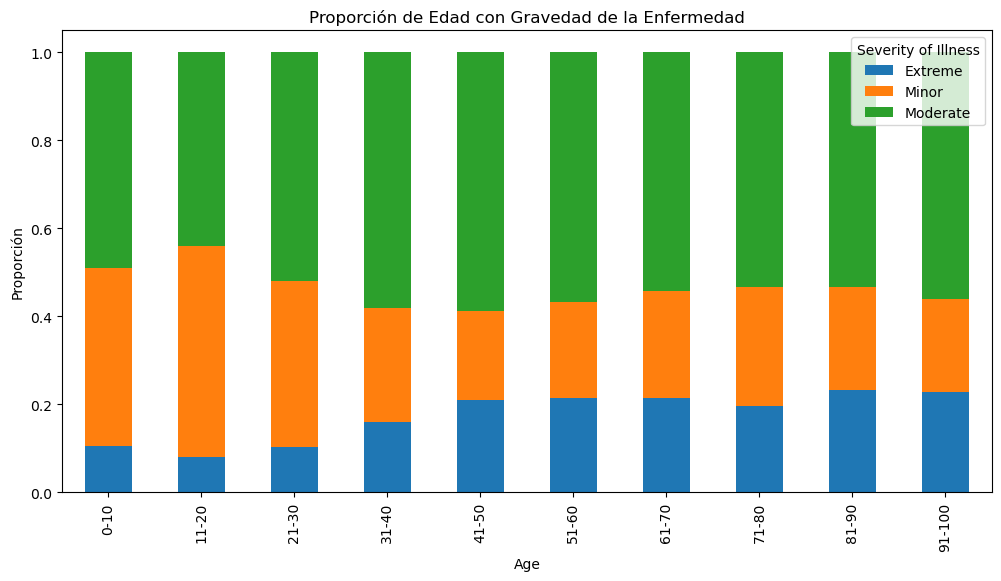

In [20]:
tabla = pd.crosstab(df_train_data_clean["Age"], df_train_data_clean["Severity of Illness"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de Edad con Gravedad de la Enfermedad")
plt.ylabel("Proporción")
plt.show()

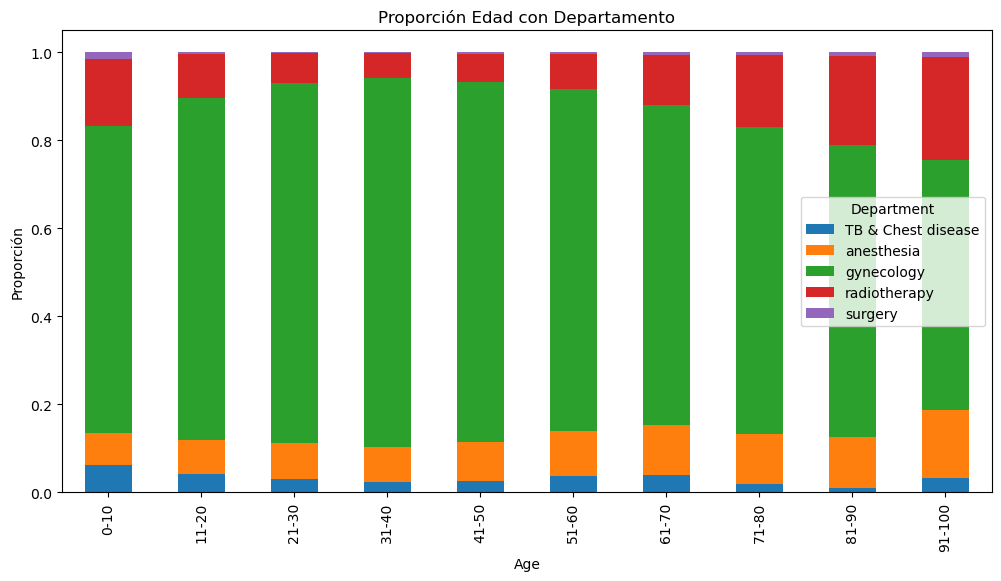

In [21]:
tabla = pd.crosstab(df_train_data_clean["Age"], df_train_data_clean["Department"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción Edad con Departamento")
plt.ylabel("Proporción")
plt.show()

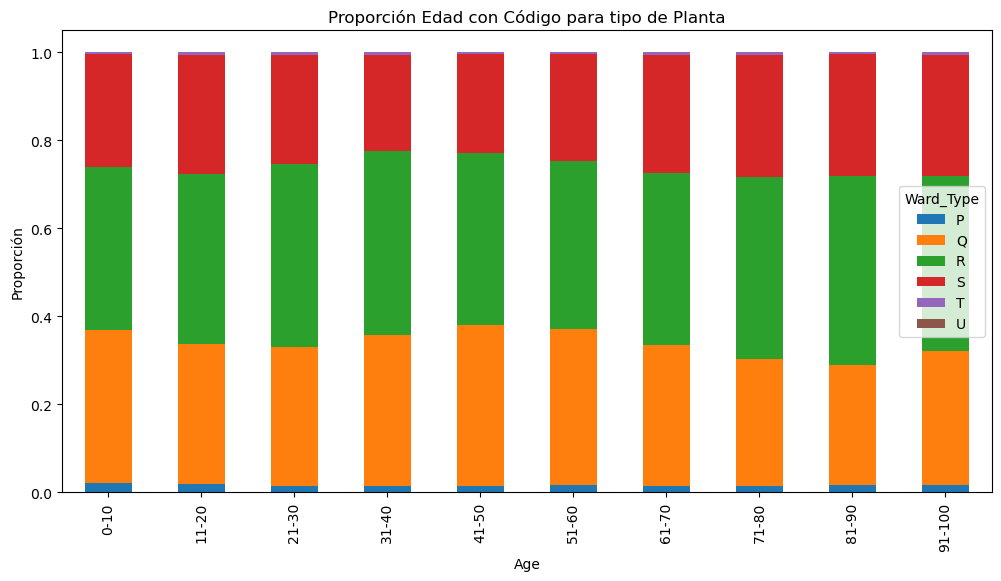

In [22]:
tabla = pd.crosstab(df_train_data_clean["Age"], df_train_data_clean["Ward_Type"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción Edad con Código para tipo de Planta")
plt.ylabel("Proporción")
plt.show()

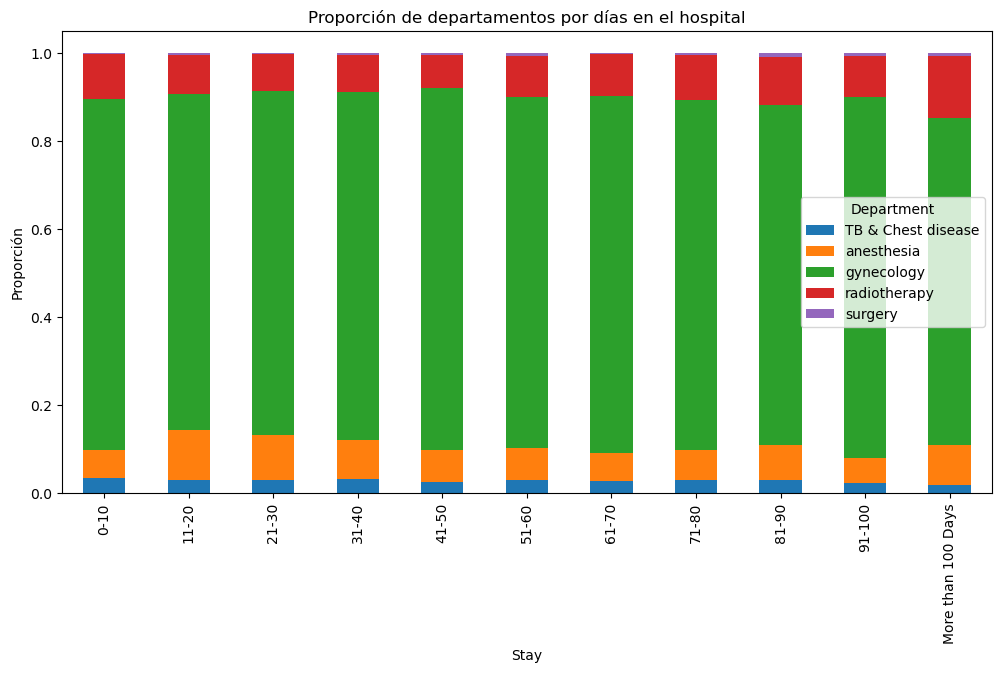

In [23]:
#Queremos ver cual es la proporción de los departamentos en relación con los días que pasan en el hospital
tabla = pd.crosstab(df_train_data_clean["Stay"], df_train_data_clean["Department"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de departamentos por días en el hospital")
plt.ylabel("Proporción")
plt.show()

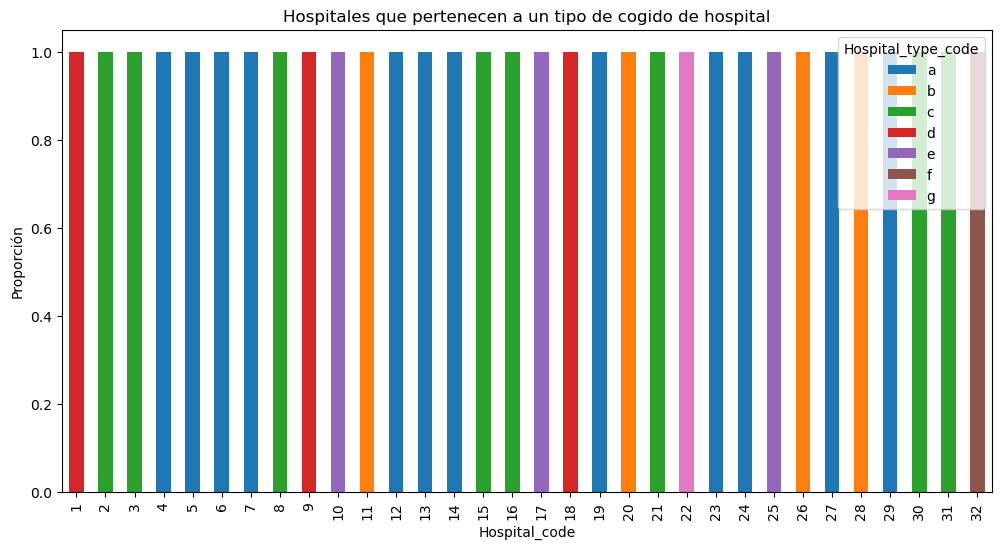

In [24]:
tabla = pd.crosstab(df_train_data_clean["Hospital_code"], df_train_data_clean["Hospital_type_code"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Hospitales que pertenecen a un tipo de cogido de hospital")
plt.ylabel("Proporción")
plt.show() 

In [ ]:
tabla = pd.crosstab(df_train_data_clean["City_Code_Hospital"], df_train_data_clean["City_Code_Patient"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Relación entre codigo ciudad y codigo ciudad paciente")
plt.ylabel("Proporción")
plt.show() 

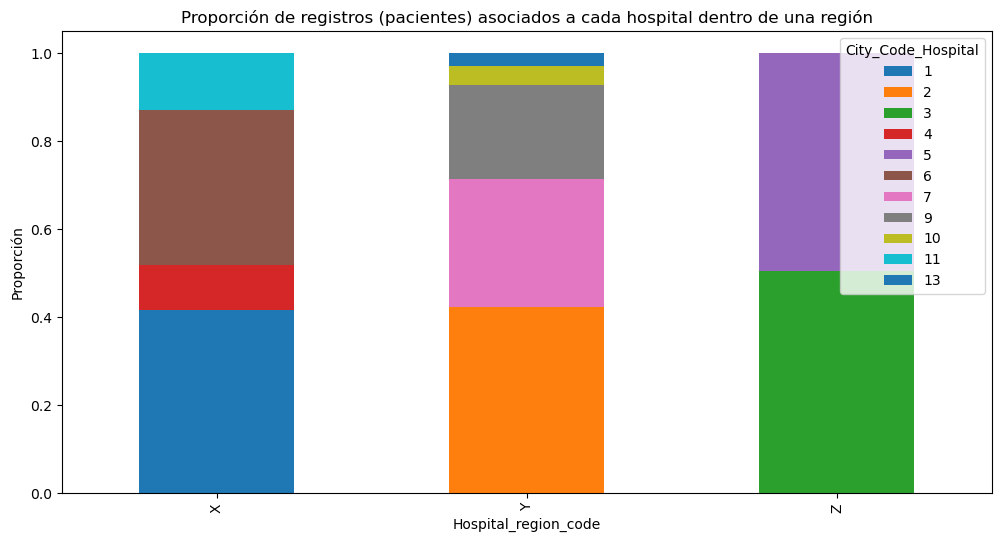

In [25]:
tabla = pd.crosstab(df_train_data_clean["Hospital_region_code"], df_train_data_clean["City_Code_Hospital"], normalize="index")

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de registros (pacientes) asociados a cada hospital dentro de una región")
plt.ylabel("Proporción")
plt.show() 

In [26]:
df_train_data_clean.groupby(["Hospital_region_code", "City_Code_Hospital"]).size()

Hospital_region_code  City_Code_Hospital
X                     1                     55351
                      4                     13854
                      6                     46882
                      11                    17137
Y                     2                     51809
                      7                     35462
                      9                     26277
                      10                     5249
                      13                     3630
Z                     3                     31569
                      5                     31105
dtype: int64

### Comprobación del código 8 para buscar patrones

In [27]:
df_train_data_clean["is_code_8"] = (
    df_train_data_clean["City_Code_Patient"] == 8
).astype(int)

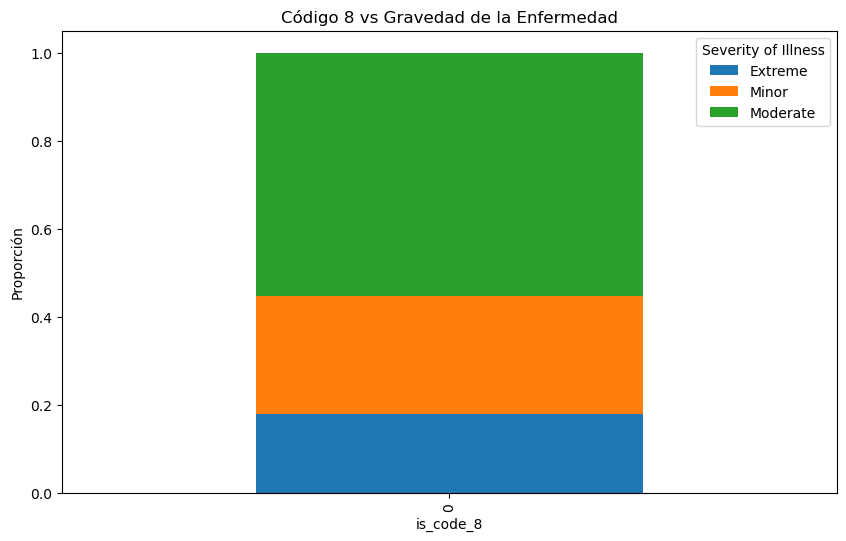

In [28]:
tabla = pd.crosstab(
    df_train_data_clean["is_code_8"],
    df_train_data_clean["Severity of Illness"],
    normalize="index"
)

tabla.plot(kind="bar", stacked=True, figsize=(10,6))
plt.title("Código 8 vs Gravedad de la Enfermedad")
plt.ylabel("Proporción")
plt.show()

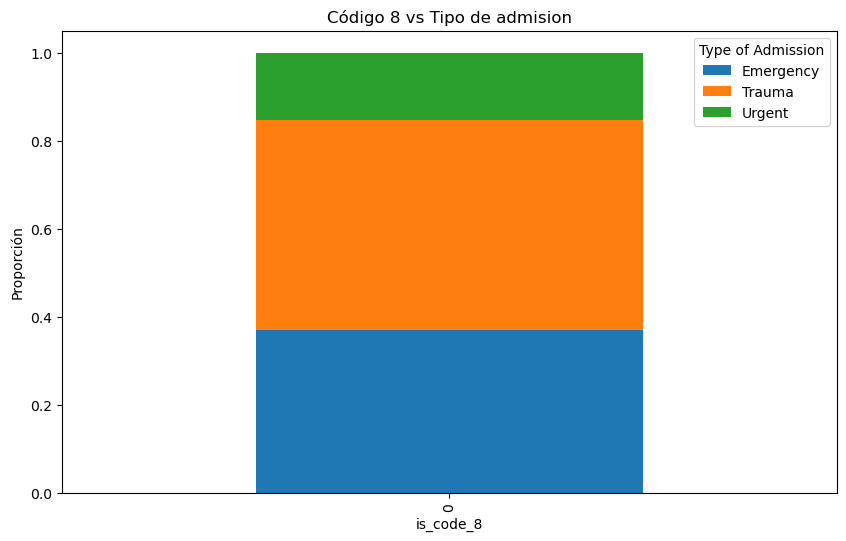

In [29]:
tabla = pd.crosstab(
    df_train_data_clean["is_code_8"],
    df_train_data_clean["Type of Admission"],
    normalize="index"
)

tabla.plot(kind="bar", stacked=True, figsize=(10,6))
plt.title("Código 8 vs Tipo de admision")
plt.ylabel("Proporción")
plt.show()

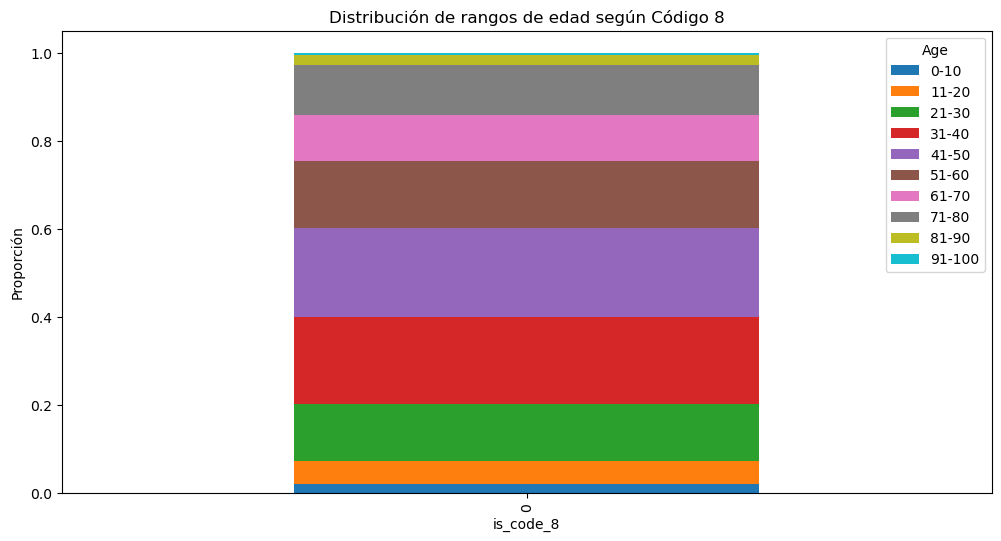

In [30]:
tabla = pd.crosstab(
    df_train_data_clean["is_code_8"],
    df_train_data_clean["Age"],
    normalize="index"
)

tabla.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Distribución de rangos de edad según Código 8")
plt.ylabel("Proporción")
plt.show()

In [31]:
#“El código 8 no muestra un patrón específico respecto a departamento, severidad o urgencia.
#Su distribución es muy similar a la distribución global del dataset, lo que sugiere que representa el código de ciudad 
#más común de paciente en el hospital.”

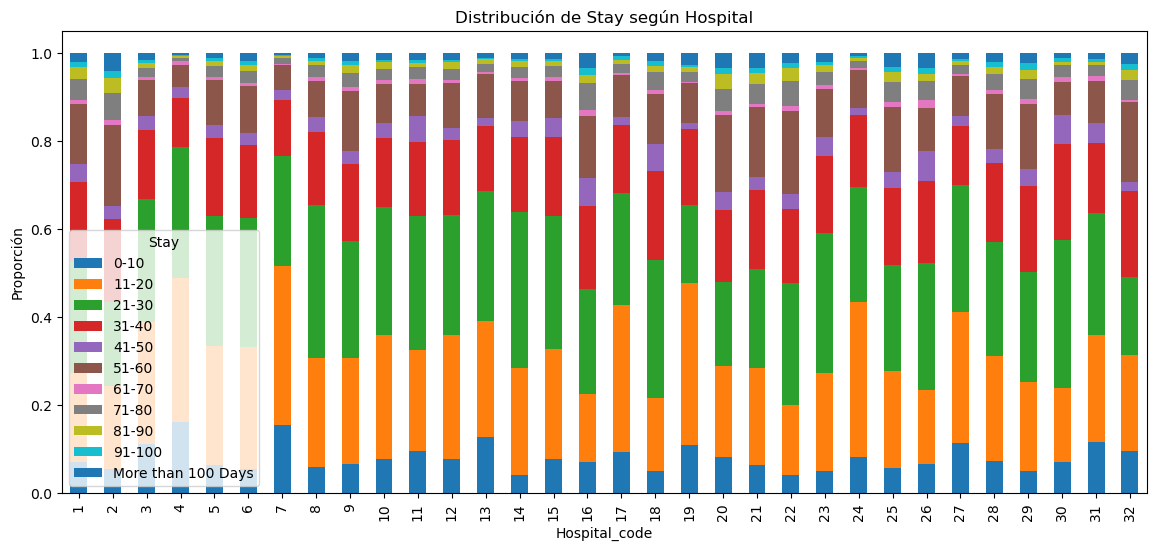

In [32]:
tabla = pd.crosstab(
    df_train_data_clean["Hospital_code"],
    df_train_data_clean["Stay"],
    normalize="index"
)

tabla.plot(kind="bar", stacked=True, figsize=(14,6))
plt.title("Distribución de Stay según Hospital")
plt.ylabel("Proporción")
plt.show()

In [33]:
df_train_data_clean.groupby("Hospital_code")["Stay"].value_counts(normalize=True)

Hospital_code  Stay              
1              21-30                 0.254334
               11-20                 0.202324
               31-40                 0.178510
               51-60                 0.136407
               0-10                  0.070299
                                       ...   
32             More than 100 Days    0.025787
               81-90                 0.023732
               41-50                 0.019060
               91-100                0.012894
               61-70                 0.004111
Name: proportion, Length: 352, dtype: float64

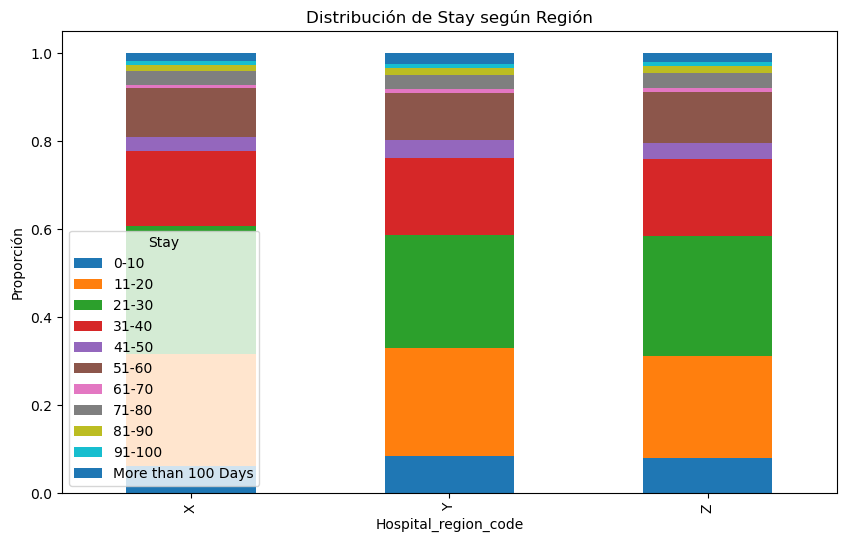

In [34]:
tabla = pd.crosstab(
    df_train_data_clean["Hospital_region_code"],
    df_train_data_clean["Stay"],
    normalize="index"
)

tabla.plot(kind="bar", stacked=True, figsize=(10,6))
plt.title("Distribución de Stay según Región")
plt.ylabel("Proporción")
plt.show()